In [ ]:
# Idea   : Locate BEATs fold checkpoints anywhere in Drive before external validation
# Goal   : Check whether fold2-4 best weights exist outside beats_5fold (or in Drive trash)
# Source : Pineau et al. 2021 (reproducibility)

import os
from google.colab import drive
drive.mount('/content/drive')

for base in ['/content/drive/MyDrive', '/content/drive/.Trash-0', '/content/drive/MyDrive/.Trash']:
    if not os.path.exists(base): continue
    for root, dirs, files in os.walk(base):
        for f in files:
            if f.endswith('.pt') and ('fold' in f.lower() or 'beats' in root.lower()):
                p = os.path.join(root, f)
                print(f'{os.path.getsize(p) / 1e6:8.1f} MB  {p}')

In [ ]:
# Idea   : External validation step 1 - internal baseline with available folds (0,1) + audit of external sound data
# Goal   : Fair internal reference (same 2-fold ensemble) and inventory of ICBHI / SPRSound files on Drive
# Source : Pineau et al. 2021 (reproducibility); Collins et al. 2024 (TRIPOD+AI, internal vs external validation)

import os, numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
from google.colab import drive
drive.mount('/content/drive')
D = '/content/drive/MyDrive/'
OUT = D + 'External_Validation/'; os.makedirs(OUT, exist_ok=True)

# 1) internal baseline: wheeze (col 3) on HF_Lung_V1 test
pf = np.load(D + 'beats_5fold/beats_test_prob_folds.npy')               # (5, 1956, 7)
y_w = (np.load(D + 'crnn_cache/test_Yf.npy', mmap_mode='r')[:, :, 3].max(1) > 0).astype(int)
print('Internal HF_Lung_V1 test - Wheeze AUC')
print(f'  5-fold ensemble      : {roc_auc_score(y_w, pf.mean(0)[:, 3]):.3f}')
print(f'  2-fold ensemble (0,1): {roc_auc_score(y_w, pf[:2].mean(0)[:, 3]):.3f}')
for k in range(5):
    print(f'  fold {k} alone         : {roc_auc_score(y_w, pf[k][:, 3]):.3f}')

# 2) inventory of external sound data
for sub in ['inception_scratch/icbhi', 'inception_scratch/sprsound']:
    p = D + sub
    print(f'\n=== {sub} ===')
    if not os.path.exists(p): print('  not found'); continue
    for root, dirs, files in os.walk(p):
        if root.count('/') - p.count('/') > 1: continue
        n_wav = sum(f.lower().endswith('.wav') for f in files)
        size = sum(os.path.getsize(os.path.join(root, f)) for f in files) / 1e6
        print(f'  {root.replace(p, ".") or "."}: {len(files)} files ({n_wav} wav), {size:.1f} MB')
        for f in sorted(files)[:5]:
            if not f.lower().endswith('.wav'): print('     ', f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Internal HF_Lung_V1 test - Wheeze AUC
  5-fold ensemble      : 0.922
  2-fold ensemble (0,1): 0.908
  fold 0 alone         : 0.890
  fold 1 alone         : 0.911
  fold 2 alone         : 0.914
  fold 3 alone         : 0.915
  fold 4 alone         : 0.917

=== inception_scratch/icbhi ===
  .: 7 files (0 wav), 418.4 MB
      X_logmel_fp16.npy
      chunks.csv
      cycles.csv
      events.csv
      frame_labels_10ms.npy

=== inception_scratch/sprsound ===
  .: 8 files (0 wav), 1618.7 MB
      X_logmel_fp16.npy
      events.csv
      frame_labels_10ms.npy
      norm.json
      recordings.csv


In [ ]:
# Idea   : Audit of existing ICBHI / SPRSound metadata (labels, recording names) before downloading raw audio
# Goal   : Reuse the same recording list and wheeze labels; BEATs needs raw 16 kHz waveforms, not cached log-mels
# Source : Rocha et al. 2019 (ICBHI 2017); Zhang et al. 2022 (SPRSound); Pineau et al. 2021

for sub, files in [('icbhi', ['cycles.csv', 'events.csv', 'chunks.csv']),
                   ('sprsound', ['recordings.csv', 'events.csv'])]:
    for f in files:
        p = D + f'inception_scratch/{sub}/{f}'
        if not os.path.exists(p): continue
        df = pd.read_csv(p)
        print(f'\n=== {sub}/{f}  shape={df.shape}')
        print('columns:', list(df.columns))
        print(df.head(3).to_string())
        for c in df.columns:
            if df[c].dtype == object and df[c].nunique() < 15:
                print(f'  {c}: {df[c].value_counts().to_dict()}')


=== icbhi/cycles.csv  shape=(6898, 6)
columns: ['stem', 'on', 'off', 'crackle', 'wheeze', 'adult']
                     stem     on    off  crackle  wheeze  adult
0  212_2b2_Tc_mc_LittC2SE  0.022  1.379        0       0   True
1  212_2b2_Tc_mc_LittC2SE  1.379  4.936        1       0   True
2  212_2b2_Tc_mc_LittC2SE  4.936  7.964        0       0   True

=== icbhi/events.csv  shape=(10775, 6)
columns: ['stem', 'on', 'off', 'type', 'adult', 'dur']
                     stem        on       off     type adult       dur
0  120_1b1_Pr_sc_Meditron  0.000000  0.117958  crackle  True  0.117958
1  120_1b1_Pr_sc_Meditron  4.839091  5.275062  crackle  True  0.435971
2  204_2b5_Ar_mc_AKGC417L  2.685000  3.054000   wheeze  True  0.369000
  type: {'crackle': 8877, 'wheeze': 1898}
  adult: {True: 10523, False: 243}

=== icbhi/chunks.csv  shape=(1716, 5)
columns: ['stem', 'pid', 'chunk', 'device', 'valid_frames']
                     stem  pid  chunk    device  valid_frames
0  212_2b2_Tc_mc_LittC2SE  

In [ ]:
# Idea   : Download raw external audio to Colab local disk (not Drive) and verify file counts against metadata
# Goal   : Raw waveforms needed by BEATs; Drive is 86% full, so audio stays on /content
# Source : Rocha et al. 2019 (ICBHI 2017 database); Zhang et al. 2022 (SPRSound, SJTU)

import subprocess, glob
os.chdir('/content')

if not os.path.exists('/content/SPRSound'):
    subprocess.run('git clone -q --depth 1 https://github.com/SJTU-YONGFU-RESEARCH-GRP/SPRSound.git', shell=True)
if not os.path.exists('/content/ICBHI_final_database'):
    subprocess.run('wget -q -O icbhi.zip "https://bhichallenge.med.auth.gr/sites/default/files/ICBHI_final_database/ICBHI_final_database.zip"'
                   ' && unzip -q icbhi.zip -d /content && rm icbhi.zip', shell=True)

spr_wavs = glob.glob('/content/SPRSound/**/*.wav', recursive=True)
icb_wavs = glob.glob('/content/ICBHI_final_database/**/*.wav', recursive=True)
spr_need = pd.read_csv(D + 'inception_scratch/sprsound/recordings.csv').stem.nunique()
icb_need = pd.read_csv(D + 'inception_scratch/icbhi/cycles.csv').stem.nunique()
spr_have = {os.path.splitext(os.path.basename(w))[0] for w in spr_wavs}
icb_have = {os.path.splitext(os.path.basename(w))[0] for w in icb_wavs}
print(f'SPRSound: {len(spr_wavs)} wav found | needed {spr_need} | matched '
      f'{len(spr_have & set(pd.read_csv(D + "inception_scratch/sprsound/recordings.csv").stem))}')
print(f'ICBHI   : {len(icb_wavs)} wav found | needed {icb_need} | matched '
      f'{len(icb_have & set(pd.read_csv(D + "inception_scratch/icbhi/cycles.csv").stem))}')

SPRSound: 20457 wav found | needed 6567 | matched 6567
ICBHI   : 0 wav found | needed 920 | matched 0


In [ ]:
# Idea   : Retry ICBHI 2017 download from the official site with visible error output
# Goal   : Diagnose the failure before switching to the Kaggle mirror of the same database
# Source : Rocha et al. 2019 (ICBHI 2017 Respiratory Sound Database)

url = 'https://bhichallenge.med.auth.gr/sites/default/files/ICBHI_final_database/ICBHI_final_database.zip'
r = subprocess.run(f'wget -O /content/icbhi.zip "{url}" 2>&1 | tail -5', shell=True, capture_output=True, text=True)
print(r.stdout)
if os.path.exists('/content/icbhi.zip'):
    print('zip size: %.1f MB' % (os.path.getsize('/content/icbhi.zip') / 1e6))

Resolving bhichallenge.med.auth.gr (bhichallenge.med.auth.gr)... 155.207.200.92
Connecting to bhichallenge.med.auth.gr (bhichallenge.med.auth.gr)|155.207.200.92|:443... connected.
ERROR: cannot verify bhichallenge.med.auth.gr's certificate, issued by ‘CN=R3,O=Let's Encrypt,C=US’:
  Issued certificate has expired.
To connect to bhichallenge.med.auth.gr insecurely, use `--no-check-certificate'.

zip size: 0.0 MB


In [ ]:
# Idea   : Download ICBHI 2017 despite the site's expired SSL certificate, then verify integrity against local metadata
# Goal   : 920 recordings whose cycle annotations match cycles.csv exactly (compensates for skipped cert check)
# Source : Rocha et al. 2019 (ICBHI 2017 Respiratory Sound Database)

subprocess.run(f'wget -q --no-check-certificate -O /content/icbhi.zip "{url}" && unzip -q -o /content/icbhi.zip -d /content && rm /content/icbhi.zip', shell=True)

icb_wavs = glob.glob('/content/ICBHI_final_database/**/*.wav', recursive=True)
icb_txts = [t for t in glob.glob('/content/ICBHI_final_database/**/*.txt', recursive=True) if '_' in os.path.basename(t)]
print('ICBHI wav:', len(icb_wavs), '| annotation txt:', len(icb_txts))

cyc = pd.read_csv(D + 'inception_scratch/icbhi/cycles.csv')
ok = bad = 0
for t in icb_txts:
    stem = os.path.splitext(os.path.basename(t))[0]
    if stem not in set(cyc.stem): continue
    a = np.loadtxt(t, ndmin=2)
    b = cyc[cyc.stem == stem][['on', 'off', 'crackle', 'wheeze']].values
    if a.shape == b.shape and np.allclose(a, b, atol=1e-3): ok += 1
    else: bad += 1
print(f'annotation check vs cycles.csv: match {ok} | mismatch {bad}')

ICBHI wav: 920 | annotation txt: 922
annotation check vs cycles.csv: match 920 | mismatch 0


In [ ]:
# Idea   : External data audit - recording-level wheeze labels, durations, sample rates, age groups, devices
# Goal   : Report the two external test sets before running BEATs (no inference in this cell)
# Source : Rocha et al. 2019 (ICBHI 2017); Zhang et al. 2022 (SPRSound); same wheeze definition as HF_Lung_V1 (Hsu et al. 2021)

import soundfile as sf

# ICBHI: wheeze if any annotated cycle has wheeze
icb = cyc.groupby('stem').agg(wheeze=('wheeze', 'max'), adult=('adult', 'first')).reset_index()
wav_map = {os.path.splitext(os.path.basename(w))[0]: w for w in icb_wavs}
icb['wav'] = icb.stem.map(wav_map)
info = [sf.info(w) for w in icb.wav]
icb['sr'], icb['dur'] = [i.samplerate for i in info], [i.duration for i in info]
icb['device'] = icb.stem.str.split('_').str[-1]
icb['patient'] = icb.stem.str.split('_').str[0]

# SPRSound: wheeze if any event contains Wheeze
spr = pd.read_csv(D + 'inception_scratch/sprsound/recordings.csv')
ev = pd.read_csv(D + 'inception_scratch/sprsound/events.csv')
w_stems = set(ev[ev['classes'].str.contains('Wheeze')].stem)
spr['wheeze'] = spr.stem.isin(w_stems).astype(int)
spr['wav'] = spr.stem.map({os.path.splitext(os.path.basename(w))[0]: w for w in spr_wavs})

for name, df in [('ICBHI 2017', icb), ('SPRSound', spr)]:
    print(f'\n===== {name} =====')
    print(f'recordings: {len(df)} | patients: {df.patient.nunique()} | wheeze recordings: {df.wheeze.sum()} ({100 * df.wheeze.mean():.1f}%)')
    print(f'duration (s): min {df.dur.min():.1f} | median {df.dur.median():.1f} | max {df.dur.max():.1f}')
    print('sample rates (Hz):', df.sr.value_counts().to_dict())
    if 'adult' in df: print('adult / child recordings:', df.adult.value_counts().to_dict())
    if 'device' in df: print('devices:', df.device.value_counts().to_dict())
    print('missing wav paths:', int(df.wav.isna().sum()))

icb.to_csv(OUT + 'icbhi_recordings.csv', index=False); spr.to_csv(OUT + 'sprsound_recordings.csv', index=False)
print('\nHF_Lung_V1 internal test for reference: 1,956 recordings, 405 wheeze (20.7%), 15 s, 4,000 Hz')


===== ICBHI 2017 =====
recordings: 920 | patients: 126 | wheeze recordings: 336 (36.5%)
duration (s): min 7.9 | median 20.0 | max 86.2
sample rates (Hz): {44100: 824, 4000: 90, 10000: 6}
adult / child recordings: {True: 837, False: 83}
devices: {'AKGC417L': 646, 'Meditron': 127, 'LittC2SE': 87, 'Litt3200': 60}
missing wav paths: 0

===== SPRSound =====
recordings: 6567 | patients: 1258 | wheeze recordings: 636 (9.7%)
duration (s): min 0.3 | median 9.2 | max 15.4
sample rates (Hz): {8000: 6567}
missing wav paths: 0

HF_Lung_V1 internal test for reference: 1,956 recordings, 405 wheeze (20.7%), 15 s, 4,000 Hz


In [ ]:
# Idea: Environment check after new Colab session
# Goal: Mount Drive, locate saved audit CSVs, verify datasets still exist in /content
# Source: Google Colab documentation (drive.mount)
from google.colab import drive
import glob, os

drive.mount('/content/drive')

for f in ['sprsound_recordings.csv', 'icbhi_recordings.csv']:
    hits = glob.glob(f'/content/drive/MyDrive/**/{f}', recursive=True)
    print(f, '->', hits if hits else 'NOT FOUND')

for d in ['/content/ICBHI_final_database', '/content/SPRSound']:
    print(d, '->', 'exists' if os.path.isdir(d) else 'MISSING')

Mounted at /content/drive
sprsound_recordings.csv -> ['/content/drive/MyDrive/External_Validation/sprsound_recordings.csv']
icbhi_recordings.csv -> ['/content/drive/MyDrive/External_Validation/icbhi_recordings.csv']
/content/ICBHI_final_database -> MISSING
/content/SPRSound -> MISSING


In [ ]:
# Idea: Pre-specified duration exclusion criterion (< 2 s) for SPRSound
# Goal: Quantify how many recordings (and wheeze cases) would be excluded before deciding
# Source: Fleming et al., Lancet 2011 (paediatric RR); Zhang et al., IEEE TBioCAS 2022 (SPRSound)
import pandas as pd

OUT = '/content/drive/MyDrive/External_Validation'
spr = pd.read_csv(f'{OUT}/sprsound_recordings.csv')
print(spr.columns.tolist())

dur_col = [c for c in spr.columns if 'dur' in c.lower()][0]
lab_col = [c for c in spr.columns if 'wheeze' in c.lower() or 'label' in c.lower()][0]

for t in [1.0, 2.0, 3.0]:
    m = spr[dur_col] < t
    print(f'< {t:.0f} s: {m.sum()} rec ({m.mean()*100:.1f}%), '
          f'wheeze excluded = {spr.loc[m, lab_col].sum()}, '
          f'remaining = {(~m).sum()} rec, wheeze = {spr.loc[~m, lab_col].sum()} '
          f'({spr.loc[~m, lab_col].mean()*100:.1f}%)')

['stem', 'wav', 'sr', 'ch', 'dur', 'patient', 'rec_label', 'wheeze']
< 1 s: 2 rec (0.0%), wheeze excluded = 0.0, remaining = 6565 rec, wheeze = 0.0 (nan%)
< 2 s: 2 rec (0.0%), wheeze excluded = 0.0, remaining = 6565 rec, wheeze = 0.0 (nan%)
< 3 s: 3 rec (0.0%), wheeze excluded = 0.0, remaining = 6564 rec, wheeze = 0.0 (nan%)


In [ ]:
# Idea: Pre-specified duration exclusion criterion (< 2 s) for SPRSound
# Goal: Fix label column, apply exclusion, save final evaluation list
# Source: Fleming et al., Lancet 2011 (paediatric RR); Zhang et al., IEEE TBioCAS 2022 (SPRSound)
import pandas as pd

OUT = '/content/drive/MyDrive/External_Validation'
spr = pd.read_csv(f'{OUT}/sprsound_recordings.csv')

m = spr['dur'] < 2.0
print(spr.loc[m, ['stem', 'dur', 'rec_label', 'wheeze']])
print(f'Excluded: {m.sum()} rec, wheeze excluded = {int(spr.loc[m, "wheeze"].sum())}')

spr_main = spr[~m].reset_index(drop=True)
print(f'Main analysis: {len(spr_main)} rec, {spr_main.patient.nunique()} patients, '
      f'wheeze = {int(spr_main.wheeze.sum())} ({spr_main.wheeze.mean()*100:.1f}%)')

spr_main.to_csv(f'{OUT}/sprsound_main.csv', index=False)
print('Saved: sprsound_main.csv')

                       stem    dur  rec_label  wheeze
3948  65039232_6.4_1_p1_373  0.304        NaN       0
6368        _3.9_0_p4_19021  0.928        NaN       0
Excluded: 2 rec, wheeze excluded = 0
Main analysis: 6565 rec, 1257 patients, wheeze = 636 (9.7%)
Saved: sprsound_main.csv


In [ ]:
# Idea: Re-download external datasets to Colab local disk (Drive is ~86% full)
# Goal: Restore ICBHI 2017 and SPRSound, verify every wav path in the saved CSVs exists
# Source: Rocha et al., Physiol. Meas. 2019 (ICBHI 2017); Zhang et al., IEEE TBioCAS 2022 (SPRSound)
import os, subprocess, pandas as pd

OUT = '/content/drive/MyDrive/External_Validation'
ICBHI_URL = 'https://bhichallenge.med.auth.gr/sites/default/files/ICBHI_final_database/ICBHI_final_database.zip'

if not os.path.isdir('/content/ICBHI_final_database'):
    subprocess.run(f'wget -q --no-check-certificate -O /content/icbhi.zip {ICBHI_URL} && '
                   f'unzip -q /content/icbhi.zip -d /content && rm /content/icbhi.zip',
                   shell=True, check=True)
if not os.path.isdir('/content/SPRSound'):
    subprocess.run('git clone -q --depth 1 https://github.com/SJTU-YONGFU-RESEARCH-GRP/SPRSound.git /content/SPRSound',
                   shell=True, check=True)

for name in ['icbhi_recordings.csv', 'sprsound_main.csv']:
    df = pd.read_csv(f'{OUT}/{name}')
    ok = df['wav'].map(os.path.isfile)
    print(f'{name}: {ok.sum()}/{len(df)} wav found')
    if (~ok).any():
        print('  missing e.g.:', df.loc[~ok, 'wav'].head(3).tolist())

icbhi_recordings.csv: 920/920 wav found
sprsound_main.csv: 6565/6565 wav found


In [ ]:
# Idea: Reproducibility check (step 1) - inspect frozen BEATs checkpoint before rebuilding model
# Goal: Read checkpoint structure, head layer names/shapes, and saved internal test probabilities
# Source: Collins et al., BMJ 2024 (TRIPOD+AI)
import torch, numpy as np, glob, os

B5 = '/content/drive/MyDrive/beats_5fold'
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE')
print(sorted(os.path.basename(f) for f in glob.glob(f'{B5}/*')))

ck = torch.load(f'{B5}/fold0_best.pt', map_location='cpu', weights_only=False)
print('top keys:', list(ck.keys()) if isinstance(ck, dict) else type(ck))
sd = ck.get('model', ck.get('state_dict', ck)) if isinstance(ck, dict) else ck
keys = list(sd.keys())
print('n params tensors:', len(keys))
print('first 3:', keys[:3])
print('non-backbone:', [(k, tuple(sd[k].shape)) for k in keys if not k.startswith(('beats.', 'backbone.', 'encoder'))][:20])

for f in glob.glob(f'{B5}/beats_test_prob*.npy'):
    print(os.path.basename(f), np.load(f).shape)

GPU: NVIDIA A100-SXM4-40GB
['beats_class_exclusion_scenarios.csv', 'beats_gradcam.png', 'beats_gradcam_500dpi.png', 'beats_gradcam_500dpi.tiff', 'beats_oof_prob.npy', 'beats_test_alert_recording.csv', 'beats_test_alert_session.csv', 'beats_test_classes_accuracy_thr.csv', 'beats_test_classes_f1_thr.csv', 'beats_test_mlcm.csv', 'beats_test_mlcm.png', 'beats_test_prob.npy', 'beats_test_prob_folds.npy', 'beats_thr_acc.npy', 'beats_thr_f1.npy', 'beats_threshold_scenarios_classes.csv', 'beats_threshold_scenarios_macro.csv', 'fold0_best.pt', 'fold0_hist.json', 'fold0_val_prob.npy', 'fold1_best.pt', 'fold1_hist.json', 'fold1_val_prob.npy', 'fold2_hist.json', 'fold2_val_prob.npy', 'fold3_hist.json', 'fold3_val_prob.npy', 'fold4_hist.json', 'fold4_val_prob.npy', 'last.pt.tmp']
top keys: ['beats.post_extract_proj.weight', 'beats.post_extract_proj.bias', 'beats.patch_embedding.weight', 'beats.encoder.pos_conv.0.bias', 'beats.encoder.pos_conv.0.weight_g', 'beats.encoder.pos_conv.0.weight_v', 'beats

In [ ]:
# Idea: Rebuild frozen BEATs classifier and load fold0/fold1 weights with strict loading
# Goal: Exact architecture match with training (BEATs -> mean over freq -> LayerNorm -> Dropout -> Linear(7))
# Source: Chen et al., ICML 2023 (BEATs); PyTorch docs (load_state_dict strict=True)
import sys, torch, torch.nn as nn, torch.nn.functional as F, torchaudio
sys.path.append('/content/drive/MyDrive/models/beats_code')
from BEATs import BEATs, BEATsConfig

DEV = 'cuda'
cfg = torch.load('/content/drive/MyDrive/models/BEATs_iter3_plus_AS2M.pt', map_location='cpu', weights_only=False)['cfg']
cfg['finetuned_model'] = False  # no AudioSet predictor head in our checkpoints

class BEATsWheeze(nn.Module):
    def __init__(self):
        super().__init__()
        self.beats = BEATs(BEATsConfig(cfg))
        self.resample = torchaudio.transforms.Resample(4000, 16000)
        self.norm, self.drop, self.fc = nn.LayerNorm(768), nn.Dropout(0.1), nn.Linear(768, 7)

    def forward(self, w4k):                                  # w4k: (B, 60000) float in [-1, 1]
        x, _ = self.beats.extract_features(self.resample(w4k))  # (B, 93*8, 768)
        x = x.view(x.size(0), -1, 8, 768).mean(2)            # mean over freq -> (B, 93, 768)
        logit = self.fc(self.drop(self.norm(x))).transpose(1, 2)  # (B, 7, 93)
        logit = F.interpolate(logit, size=938, mode='linear', align_corners=False)
        frame = torch.sigmoid(logit)                         # (B, 7, 938)
        clip = F.avg_pool1d(frame, 9, 1, 4).amax(-1)         # (B, 7)
        return clip, frame

models = []
for k in [0, 1]:
    m = BEATsWheeze()
    sd = torch.load(f'/content/drive/MyDrive/beats_5fold/fold{k}_best.pt', map_location='cpu', weights_only=False)
    print(f'fold{k}:', m.load_state_dict(sd, strict=True))
    models.append(m.to(DEV).eval())

with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
    c, f = models[0](torch.zeros(2, 60000, device=DEV))
print('clip', tuple(c.shape), 'frame', tuple(f.shape))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold0: <All keys matched successfully>
fold1: <All keys matched successfully>
clip (2, 7) frame (2, 7, 938)


In [ ]:
# Idea: Reproducibility check (step 2) - locate internal test order used for saved probabilities
# Goal: Find the HF_Lung_V1 test name list (crnn_cache order) and any saved waveform cache
# Source: Collins et al., BMJ 2024 (TRIPOD+AI)
import glob, os

ROOT = '/content/drive/MyDrive'
pats = ['**/*crnn*', '**/*names*', '**/*wave*cache*', '**/*test*.csv', '**/*test*.txt', '**/*test*names*.npy']
seen = set()
for p in pats:
    for f in glob.glob(f'{ROOT}/{p}', recursive=True):
        if f not in seen and 'External_Validation' not in f:
            seen.add(f)
            sz = os.path.getsize(f) / 1e6 if os.path.isfile(f) else 0
            print(f'{sz:8.2f} MB  {f.replace(ROOT, "")}')

In [ ]:
# Idea: Reproducibility check (step 3) - restore HF_Lung_V1 raw audio for internal test set
# Goal: Clone official repo, extract 7z archives, match every name in test_names.npy to a wav file
# Source: Hsu et al., PLoS ONE 2021 (HF_Lung_V1, gitlab.com/techsupportHF/HF_Lung_V1)
import os, glob, subprocess, numpy as np

HF = '/content/HF_Lung_V1'
if not os.path.isdir(HF):
    subprocess.run(f'git clone -q --depth 1 https://gitlab.com/techsupportHF/HF_Lung_V1.git {HF}', shell=True, check=True)
    if subprocess.run('which 7z', shell=True).returncode != 0:
        subprocess.run('apt-get -qq install -y p7zip-full', shell=True, check=True)
    for z in sorted(glob.glob(f'{HF}/**/*.7z', recursive=True)):
        subprocess.run(f'7z x -y -bd -o"{os.path.dirname(z)}" "{z}" > /dev/null', shell=True, check=True)

wav_map = {os.path.splitext(os.path.basename(f))[0]: f for f in glob.glob(f'{HF}/**/*.wav', recursive=True)}
test_names = np.load('/content/drive/MyDrive/crnn_cache/test_names.npy', allow_pickle=True)
print('wav files:', len(wav_map), '| test names:', len(test_names), '| first:', test_names[:3])

stems = [os.path.splitext(os.path.basename(str(n)))[0] for n in test_names]
found = sum(s in wav_map for s in stems)
print(f'test matched: {found}/{len(stems)}')

wav files: 0 | test names: 1956 | first: ['steth_20190801_09_46_05' 'steth_20190801_09_46_26'
 'steth_20190801_09_46_51']
test matched: 0/1956


In [ ]:
# Idea: Inspect cloned HF_Lung_V1 repository structure
# Goal: Identify archive format (7z / zip / split parts / Git LFS pointers) before extraction
# Source: Hsu et al., PLoS ONE 2021 (HF_Lung_V1)
import os, collections

HF = '/content/HF_Lung_V1'
ext = collections.Counter()
for r, _, fs in os.walk(HF):
    if '/.git' in r:
        continue
    for f in fs:
        p = os.path.join(r, f)
        ext[os.path.splitext(f)[1].lower()] += 1
        if os.path.getsize(p) > 1e6 or r == HF:
            print(f'{os.path.getsize(p)/1e6:9.1f} MB  {p.replace(HF, "")}')
print(dict(ext))

     94.4 MB  /train.7z.003
     94.4 MB  /train.7z.008
     94.4 MB  /train.7z.001
     94.4 MB  /train.7z.004
     90.2 MB  /train.7z.010
      0.0 MB  /LICENSE
      0.0 MB  /README.md
     94.4 MB  /train.7z.009
     94.4 MB  /train.7z.002
     94.4 MB  /test.7z.001
     94.4 MB  /train.7z.007
     94.4 MB  /test.7z.002
     46.5 MB  /test.7z.003
     94.4 MB  /train.7z.006
     94.4 MB  /train.7z.005
      0.0 MB  /Disclaimer
{'.003': 2, '.008': 1, '.001': 2, '.004': 1, '.010': 1, '': 2, '.md': 1, '.009': 1, '.002': 2, '.007': 1, '.006': 1, '.005': 1}


In [ ]:
# Idea: Extract split 7z archive (test part only) for reproducibility check
# Goal: Unpack test.7z.001-003 and match all 1956 test names to wav files
# Source: Hsu et al., PLoS ONE 2021 (HF_Lung_V1)
import os, glob, subprocess, numpy as np

HF = '/content/HF_Lung_V1'
if subprocess.run('which 7z', shell=True, capture_output=True).returncode != 0:
    subprocess.run('apt-get -qq install -y p7zip-full', shell=True, check=True)
subprocess.run(f'7z x -y -bd -o"{HF}" "{HF}/test.7z.001" > /dev/null', shell=True, check=True)

wav_map = {os.path.splitext(os.path.basename(f))[0]: f for f in glob.glob(f'{HF}/**/*.wav', recursive=True)}
test_names = np.load('/content/drive/MyDrive/crnn_cache/test_names.npy', allow_pickle=True)
stems = [str(n) for n in test_names]
print('wav files:', len(wav_map), '| test matched:', sum(s in wav_map for s in stems), '/', len(stems))

wav files: 1956 | test matched: 1956 / 1956


In [ ]:
# Idea: Reproducibility check (step 4) - run frozen fold0/fold1 on internal HF_Lung_V1 test
# Goal: Confirm new probabilities match saved beats_test_prob_folds.npy (r ~ 1, small |diff|, wheeze AUC 0.908)
# Source: Collins et al., BMJ 2024 (TRIPOD+AI)
import soundfile as sf, torchaudio.functional as AF, pandas as pd
from sklearn.metrics import roc_auc_score

def load_4k(path, n=60000):
    w, sr = sf.read(path, dtype='float32', always_2d=True)
    w = torch.from_numpy(w.mean(1))
    if sr != 4000:
        w = AF.resample(w, sr, 4000)
    return F.pad(w, (0, max(0, n - len(w))))[:n]

@torch.no_grad()
def predict(model, wavs, bs=32):
    out = []
    for i in range(0, len(wavs), bs):
        x = torch.stack(wavs[i:i+bs]).to(DEV)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            out.append(model(x)[0].float().cpu())
    return torch.cat(out).numpy()

wavs = [load_4k(wav_map[s]) for s in stems]
saved = np.load('/content/drive/MyDrive/beats_5fold/beats_test_prob_folds.npy')
new = np.stack([predict(m, wavs) for m in models])  # (2, 1956, 7)
np.save('/content/drive/MyDrive/External_Validation/repro_test_prob_folds01.npy', new)

for k in [0, 1]:
    r = np.corrcoef(new[k].ravel(), saved[k].ravel())[0, 1]
    print(f'fold{k}: r = {r:.6f} | max|diff| = {np.abs(new[k]-saved[k]).max():.4f} | '
          f'wheeze r = {np.corrcoef(new[k][:, 3], saved[k][:, 3])[0, 1]:.6f}')

y_w = (saved[:, :, 3].mean(0) > -1)  # placeholder shape check
print('shapes new/saved:', new.shape, saved.shape)

fold0: r = 0.929028 | max|diff| = 0.9903 | wheeze r = 0.920904
fold1: r = 0.975160 | max|diff| = 0.6477 | wheeze r = 0.968758
shapes new/saved: (2, 1956, 7) (5, 1956, 7)


In [ ]:
# Idea: Reproducibility check (step 5) - performance-level agreement on internal test
# Goal: Build recording-level wheeze labels from HF_Lung_V1 label files, compare AUC of saved vs new probabilities
# Source: Hsu et al., PLoS ONE 2021 (label format); Collins et al., BMJ 2024 (TRIPOD+AI)
import collections

lab_map = {os.path.basename(f).replace('_label.txt', ''): f for f in glob.glob(f'{HF}/**/*_label.txt', recursive=True)}
print('label files matched:', sum(s in lab_map for s in stems), '/', len(stems))

tok = collections.Counter()
rec_tokens = []
for s in stems:
    t = {ln.split()[0] for ln in open(lab_map[s]) if ln.strip()}
    tok.update(t); rec_tokens.append(t)
print('event types (recordings containing):', dict(tok))

y = np.array([any(x.lower().startswith('w') for x in t) for t in rec_tokens], int)
print(f'wheeze recordings: {y.sum()} ({y.mean()*100:.1f}%)')

auc = lambda p: roc_auc_score(y, p[:, 3])
print(f'SAVED  fold0 {auc(saved[0]):.3f} | fold1 {auc(saved[1]):.3f} | 2-fold {auc(saved[:2].mean(0)):.3f}')
print(f'NEW    fold0 {auc(new[0]):.3f} | fold1 {auc(new[1]):.3f} | 2-fold {auc(new.mean(0)):.3f}')

label files matched: 1956 / 1956
event types (recordings containing): {'D': 368, 'I': 1935, 'E': 950, 'Wheeze': 405, 'Stridor': 12, 'Rhonchi': 296}
wheeze recordings: 405 (20.7%)
SAVED  fold0 0.890 | fold1 0.911 | 2-fold 0.908
NEW    fold0 0.862 | fold1 0.889 | 2-fold 0.887


In [ ]:
# Idea: Exact replica of training-time forward (fbank in fp32 outside autocast; int16 ch0 / 32768)
# Goal: Reproduce saved fold0/fold1 test probabilities (target r >= 0.999, AUC 0.890 / 0.911 / 0.908)
# Source: Micikevicius et al., ICLR 2018 (mixed precision); Collins et al., BMJ 2024 (TRIPOD+AI)
def fwd_train_exact(m, wav):                       # wav: (B, 60000) float in [-1, 1]
    b = m.beats
    with torch.autocast('cuda', enabled=False):
        fb = b.preprocess(m.resample(wav.float()))  # (B, 1498, 128) in fp32
    x = b.patch_embedding(fb.unsqueeze(1)); Tt, Ff = x.shape[2], x.shape[3]
    x = b.layer_norm(x.flatten(2).transpose(1, 2))
    if b.post_extract_proj is not None: x = b.post_extract_proj(x)
    x, _ = b.encoder(b.dropout_input(x), padding_mask=None)
    x = x.reshape(x.shape[0], Tt, Ff, -1).mean(2)
    z = m.fc(m.drop(m.norm(x))).float()             # (B, 93, 7)
    z = F.interpolate(z.transpose(1, 2), size=938, mode='linear', align_corners=False)
    return F.avg_pool1d(torch.sigmoid(z), 9, stride=1, padding=4).amax(-1)  # (B, 7)

def read_int16(path, n=60000):
    y, sr = sf.read(path, dtype='int16', always_2d=True)
    assert sr == 4000, sr
    out = np.zeros(n, np.int16); out[:min(len(y), n)] = y[:n, 0]
    return out

@torch.no_grad()
def predict_exact(m, W, bs=32):
    out = []
    for i in range(0, len(W), bs):
        x = torch.from_numpy(W[i:i+bs]).to(DEV).float() / 32768
        with torch.autocast('cuda', dtype=torch.bfloat16):
            out.append(fwd_train_exact(m, x).float().cpu())
    return torch.cat(out).numpy()

W = np.stack([read_int16(wav_map[s]) for s in stems])
new = np.stack([predict_exact(m, W) for m in models])
np.save('/content/drive/MyDrive/External_Validation/repro_test_prob_folds01.npy', new)

for k in [0, 1]:
    print(f'fold{k}: r = {np.corrcoef(new[k].ravel(), saved[k].ravel())[0,1]:.6f} | '
          f'max|diff| = {np.abs(new[k]-saved[k]).max():.4f} | wheeze AUC new {auc(new[k]):.3f} vs saved {auc(saved[k]):.3f}')
print(f'2-fold wheeze AUC: new {auc(new.mean(0)):.3f} vs saved {auc(saved[:2].mean(0)):.3f}')

fold0: r = 0.999997 | max|diff| = 0.0164 | wheeze AUC new 0.890 vs saved 0.890
fold1: r = 0.999999 | max|diff| = 0.0082 | wheeze AUC new 0.911 vs saved 0.911
2-fold wheeze AUC: new 0.908 vs saved 0.908


In [ ]:
# Idea: External inference with frozen BEATs (fold0+fold1), identical training-time forward
# Goal: Resample to 4 kHz, 15-s chunks (drop tail < 2 s, pad short), recording prob = max over chunks; save probs
# Source: Smith, CCRMA (bandlimited resampling); Wang et al., ICASSP 2019 (max pooling); Chen et al., ICML 2023 (BEATs)
import torchaudio.functional as AF
from tqdm.auto import tqdm

OUT, L, MIN_TAIL = '/content/drive/MyDrive/External_Validation', 60000, 8000

def chunks_4k(path):
    y, sr = sf.read(path, dtype='float32', always_2d=True)
    w = torch.from_numpy(y[:, 0].copy())
    if sr != 4000:
        w = AF.resample(w, sr, 4000)
    w = w.clamp(-1, 1)
    segs = [w[i:i+L] for i in range(0, max(len(w), 1), L)]
    segs = [s for j, s in enumerate(segs) if j == 0 or len(s) >= MIN_TAIL]
    return torch.stack([F.pad(s, (0, L - len(s))) for s in segs])

@torch.no_grad()
def run_dataset(df, bs=32):
    X, owner = [], []
    for i, p in enumerate(tqdm(df['wav'], desc='load')):
        c = chunks_4k(p); X.append(c); owner += [i] * len(c)
    X, owner = torch.cat(X), np.array(owner)
    P = np.full((2, len(df), 7), -np.inf, np.float32)
    for k, m in enumerate(models):
        for i in tqdm(range(0, len(X), bs), desc=f'fold{k}'):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                p = fwd_train_exact(m, X[i:i+bs].to(DEV)).float().cpu().numpy()
            np.maximum.at(P[k], owner[i:i+bs], p)
    return P, np.bincount(owner, minlength=len(df))

for name, csv in [('icbhi', 'icbhi_recordings.csv'), ('sprsound', 'sprsound_main.csv')]:
    df = pd.read_csv(f'{OUT}/{csv}')
    P, nch = run_dataset(df)
    np.save(f'{OUT}/{name}_prob_folds01.npy', P)
    df['n_chunks'], df['p_wheeze'] = nch, P[:, :, 3].mean(0)
    df.to_csv(f'{OUT}/{name}_pred.csv', index=False)
    print(f'{name}: {len(df)} rec, {nch.sum()} chunks, p_wheeze mean = {df.p_wheeze.mean():.3f}')

load:   0%|          | 0/920 [00:00<?, ?it/s]

fold0:   0%|          | 0/60 [00:00<?, ?it/s]

fold1:   0%|          | 0/60 [00:00<?, ?it/s]

icbhi: 920 rec, 1909 chunks, p_wheeze mean = 0.298


load:   0%|          | 0/6565 [00:00<?, ?it/s]

fold0:   0%|          | 0/206 [00:00<?, ?it/s]

fold1:   0%|          | 0/206 [00:00<?, ?it/s]

sprsound: 6565 rec, 6565 chunks, p_wheeze mean = 0.158


In [ ]:
# Idea: External validation metrics with frozen OOF thresholds + patient-level cluster bootstrap CI
# Goal: Wheeze Accuracy/Precision/Recall/F1/AUC on internal test vs ICBHI 2017 vs SPRSound (no re-tuning)
# Source: Steyerberg, Clinical Prediction Models 2019; Field & Welsh, JRSS-B 2007 (cluster bootstrap)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

B5 = '/content/drive/MyDrive/beats_5fold'
thr = {'F1-optimal': float(np.load(f'{B5}/beats_thr_f1.npy')[3]),
       'Accuracy-optimal': float(np.load(f'{B5}/beats_thr_acc.npy')[3])}
print('frozen wheeze thresholds:', {k: round(v, 3) for k, v in thr.items()})

def auc_ci(y, p, groups, n=1000, seed=0):
    rng, ug = np.random.default_rng(seed), np.unique(groups)
    idx = {g: np.where(groups == g)[0] for g in ug}
    a = []
    for _ in range(n):
        s = np.concatenate([idx[g] for g in rng.choice(ug, len(ug))])
        if y[s].min() != y[s].max():
            a.append(roc_auc_score(y[s], p[s]))
    return np.percentile(a, [2.5, 97.5])

ic = pd.read_csv(f'{OUT}/icbhi_pred.csv'); sp = pd.read_csv(f'{OUT}/sprsound_pred.csv')
sets = {'HF_Lung_V1 internal test': (y, new.mean(0)[:, 3], np.arange(len(y))),
        'ICBHI 2017': (ic.wheeze.values.astype(int), ic.p_wheeze.values, ic.patient.values),
        'SPRSound': (sp.wheeze.values.astype(int), sp.p_wheeze.values, sp.patient.values)}

rows = []
for ds, (yt, p, g) in sets.items():
    lo, hi = auc_ci(yt, p, g)
    for tn, t in thr.items():
        yh = (p >= t).astype(int)
        rows.append({'Dataset': ds, 'Threshold': f'{tn} ({t:.2f})', 'N': len(yt), 'Wheeze %': f'{yt.mean()*100:.1f}',
                     'Accuracy': accuracy_score(yt, yh), 'Precision': precision_score(yt, yh, zero_division=0),
                     'Recall': recall_score(yt, yh), 'F1': f1_score(yt, yh),
                     'AUC': roc_auc_score(yt, p), 'AUC 95% CI': f'{lo:.3f}-{hi:.3f}'})
res = pd.DataFrame(rows)
res.to_csv(f'{OUT}/sound_external_metrics.csv', index=False)
display(res.style.format({c: '{:.3f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']}).hide(axis='index'))

frozen wheeze thresholds: {'F1-optimal': 0.43, 'Accuracy-optimal': 0.8}


Dataset,Threshold,N,Wheeze %,Accuracy,Precision,Recall,F1,AUC,AUC 95% CI
HF_Lung_V1 internal test,F1-optimal (0.43),1956,20.7,0.869,0.670,0.726,0.697,0.908,0.892-0.924
HF_Lung_V1 internal test,Accuracy-optimal (0.80),1956,20.7,0.869,0.782,0.506,0.615,0.908,0.892-0.924
ICBHI 2017,F1-optimal (0.43),920,36.5,0.809,0.778,0.667,0.718,0.869,0.826-0.907
ICBHI 2017,Accuracy-optimal (0.80),920,36.5,0.767,0.814,0.470,0.596,0.869,0.826-0.907
SPRSound,F1-optimal (0.43),6565,9.7,0.870,0.401,0.692,0.507,0.896,0.876-0.918
SPRSound,Accuracy-optimal (0.80),6565,9.7,0.910,0.547,0.426,0.479,0.896,0.876-0.918


In [ ]:
# Idea: Subgroup analysis on ICBHI 2017 (age group, recording device) with frozen F1-optimal threshold
# Goal: Check whether wheeze detection degrades for a specific population or stethoscope
# Source: Collins et al., BMJ 2024 (TRIPOD+AI, subgroup / fairness reporting)
print(ic.columns.tolist())
t = thr['F1-optimal']

if 'device' not in ic.columns:
    ic['device'] = ic['stem'].str.split('_').str[-1]
age_col = next((c for c in ic.columns if c.lower() in ['age_group', 'group', 'adult', 'child', 'is_child']), None)
if age_col is None and 'age' in ic.columns:
    ic['age_group'] = np.where(ic['age'] < 18, 'Child', 'Adult'); age_col = 'age_group'

rows = []
for col in [age_col, 'device']:
    for g, d in ic.groupby(col):
        yt, p = d.wheeze.values.astype(int), d.p_wheeze.values
        yh = (p >= t).astype(int)
        rows.append({'Subgroup': f'{col} = {g}', 'N rec': len(d), 'Patients': d.patient.nunique(),
                     'Wheeze': int(yt.sum()), 'Accuracy': accuracy_score(yt, yh),
                     'Precision': precision_score(yt, yh, zero_division=0), 'Recall': recall_score(yt, yh, zero_division=0),
                     'F1': f1_score(yt, yh, zero_division=0),
                     'AUC': roc_auc_score(yt, p) if 0 < yt.sum() < len(yt) else np.nan})
sub = pd.DataFrame(rows)
sub.to_csv(f'{OUT}/sound_icbhi_subgroups.csv', index=False)
display(sub.style.format({c: '{:.3f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']}, na_rep='-').hide(axis='index'))

['stem', 'wheeze', 'adult', 'wav', 'sr', 'dur', 'device', 'patient', 'n_chunks', 'p_wheeze']


Subgroup,N rec,Patients,Wheeze,Accuracy,Precision,Recall,F1,AUC
adult = False,83,51,20,0.831,0.714,0.500,0.588,0.896
adult = True,837,75,316,0.806,0.781,0.677,0.725,0.865
device = AKGC417L,646,32,230,0.830,0.885,0.600,0.715,0.880
device = Litt3200,60,11,31,0.500,0.508,0.968,0.667,0.711
device = LittC2SE,87,23,37,0.874,0.933,0.757,0.836,0.962
device = Meditron,127,64,38,0.803,0.651,0.737,0.691,0.895


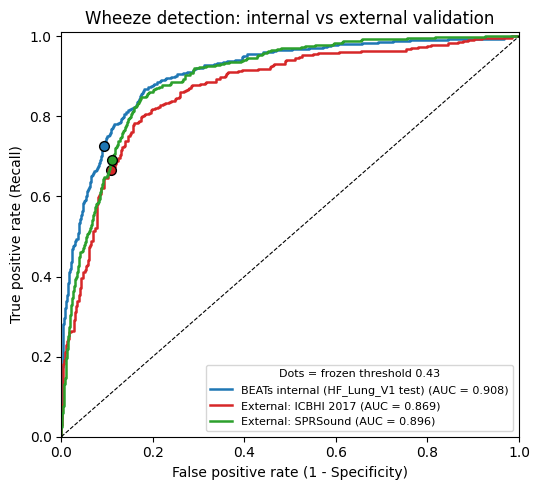

In [ ]:
# Idea: ROC curves - internal vs external (ICBHI 2017, SPRSound), frozen F1-optimal operating point marked
# Goal: Single publication figure summarising sound-path generalisation (500 dpi PNG + TIFF)
# Source: Fawcett, Pattern Recognition Letters 2006 (ROC analysis)
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

names = {'HF_Lung_V1 internal test': 'BEATs internal (HF_Lung_V1 test)',
         'ICBHI 2017': 'External: ICBHI 2017', 'SPRSound': 'External: SPRSound'}
fig, ax = plt.subplots(figsize=(5.5, 5))
for (ds, (yt, p, _)), c in zip(sets.items(), ['#1f77b4', '#d62728', '#2ca02c']):
    fpr, tpr, _ = roc_curve(yt, p)
    ax.plot(fpr, tpr, c=c, lw=1.8, label=f'{names[ds]} (AUC = {roc_auc_score(yt, p):.3f})')
    yh = p >= thr['F1-optimal']
    ax.plot((yh & (yt == 0)).sum() / (yt == 0).sum(), (yh & (yt == 1)).sum() / (yt == 1).sum(),
            'o', c=c, ms=7, mec='k')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set(xlabel='False positive rate (1 - Specificity)', ylabel='True positive rate (Recall)',
       title='Wheeze detection: internal vs external validation', xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc='lower right', fontsize=8, title='Dots = frozen threshold 0.43', title_fontsize=8)
plt.tight_layout()
for ext in ['png', 'tiff']:
    plt.savefig(f'{OUT}/sound_external_roc_500dpi.{ext}', dpi=500)
plt.show()

In [ ]:
# Idea: Final check of saved external-validation outputs on Drive
# Goal: List every result file with its size before closing Colab
# Source: -
import os
EV = '/content/drive/MyDrive/External_Validation'
for f in sorted(os.listdir(EV)):
    p = f'{EV}/{f}'
    print(f'{os.path.getsize(p)/1e6:8.2f} MB  {f}' if os.path.isfile(p) else f'   [folder]  {f}/')

In [ ]:
# Idea: download the saved high-resolution ROC figure (500 dpi) from Drive
# Goal: use the original figure in the paper instead of a screenshot
from google.colab import drive, files
from PIL import Image
import os

drive.mount('/content/drive')
path = '/content/drive/MyDrive/External_Validation/sound_external_roc_500dpi.png'
print('exists:', os.path.exists(path))
im = Image.open(path)
print('size (px):', im.size, '| dpi:', im.info.get('dpi'))
files.download(path)

Mounted at /content/drive
exists: True
size (px): (2750, 2500) | dpi: (499.99899999999997, 499.99899999999997)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

font used: Times New Roman


NameError: name 'sets' is not defined

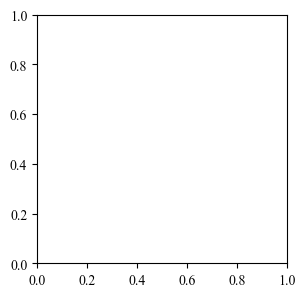

In [ ]:
# Idea: re-draw the ROC figure to match the journal template rules
# Goal: single-column width (8.2 cm), all text Times New Roman 10 pt, no title, 300 dpi
# Source: journal_Format.docx (Ver. 2026.10.1) - figure rules; Fawcett, Pattern Recognition Letters 2006 (ROC analysis)
import subprocess, matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.metrics import roc_curve, roc_auc_score

# install Times New Roman on Colab (falls back to Liberation Serif, a metric-compatible Times font)
subprocess.run('echo ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true | debconf-set-selections && '
               'apt-get -qq install -y ttf-mscorefonts-installer > /dev/null 2>&1', shell=True)
for f in font_manager.findSystemFonts(): font_manager.fontManager.addfont(f)
fam = 'Times New Roman' if any('Times New Roman' in f.name for f in font_manager.fontManager.ttflist) else 'Liberation Serif'
plt.rcParams.update({'font.family': fam, 'font.size': 10, 'axes.titlesize': 10, 'axes.labelsize': 10,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10})
print('font used:', fam)

names = {'HF_Lung_V1 internal test': 'HF_Lung_V1 (internal)',
         'ICBHI 2017': 'ICBHI 2017 (external)', 'SPRSound': 'SPRSound (external)'}
cm = 1 / 2.54
fig, ax = plt.subplots(figsize=(8.2 * cm, 8.2 * cm))
for (ds, (yt, p, _)), c in zip(sets.items(), ['#1f77b4', '#d62728', '#2ca02c']):
    fpr, tpr, _ = roc_curve(yt, p)
    ax.plot(fpr, tpr, c=c, lw=1.2, label=f'{names[ds]}, AUC = {roc_auc_score(yt, p):.3f}')
    yh = p >= thr['F1-optimal']
    ax.plot((yh & (yt == 0)).sum() / (yt == 0).sum(), (yh & (yt == 1)).sum() / (yt == 1).sum(),
            'o', c=c, ms=5, mec='k', mew=0.6)
ax.plot([0, 1], [0, 1], 'k--', lw=0.7)
ax.set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc='lower right', frameon=False, handlelength=1.2, borderaxespad=0.2)
plt.tight_layout(pad=0.3)
for ext in ['png', 'tiff']:
    plt.savefig(f'{OUT}/fig4_roc_journal_300dpi.{ext}', dpi=300)
plt.show()

In [ ]:
# Idea: reload the saved external-validation outputs instead of re-running the model
# Goal: check the saved files and their contents before rebuilding the ROC figure
# Source: files saved earlier in External_Validation/ (frozen BEATs fold0+fold1)
import os, numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')
EV = '/content/drive/MyDrive/External_Validation'
OUT = EV
for f in sorted(os.listdir(EV)):
    if f.endswith(('.npy', '.csv')):
        p = f'{EV}/{f}'
        if f.endswith('.npy'):
            a = np.load(p, allow_pickle=True); print(f, '| shape', a.shape)
        else:
            d = pd.read_csv(p); print(f, '| rows', len(d), '| columns', list(d.columns))

HF_Lung_V1 (internal): N=1956 | wheeze=405 | AUC=0.908
ICBHI 2017 (external): N=920 | wheeze=336 | AUC=0.869
SPRSound (external): N=6565 | wheeze=636 | AUC=0.896


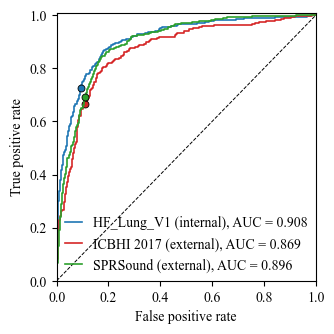

In [ ]:
# Idea: rebuild the ROC figure from the saved probabilities, following the journal figure rules
# Goal: 8.2 cm single-column figure, Times New Roman 10 pt, 300 dpi; check AUCs match the paper (0.908 / 0.869 / 0.896)
# Source: journal_Format.docx (Ver. 2026.10.1); Fawcett, Pattern Recognition Letters 2006 (ROC analysis)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

EV = '/content/drive/MyDrive/External_Validation'
Yf = np.load('/content/drive/MyDrive/crnn_cache/test_Yf.npy', mmap_mode='r')
y_hf = (np.asarray(Yf[..., 3]).max(1) > 0).astype(int)                 # wheeze = class index 3
p_hf = np.load(f'{EV}/repro_test_prob_folds01.npy')[:, :, 3].mean(0)  # mean of fold0 + fold1
ic, sp = pd.read_csv(f'{EV}/icbhi_pred.csv'), pd.read_csv(f'{EV}/sprsound_pred.csv')
sets = {'HF_Lung_V1 (internal)': (y_hf, p_hf),
        'ICBHI 2017 (external)': (ic['wheeze'].values, ic['p_wheeze'].values),
        'SPRSound (external)':   (sp['wheeze'].values, sp['p_wheeze'].values)}
THR = 0.43
for k, (yt, p) in sets.items():
    print(f'{k}: N={len(yt)} | wheeze={int(yt.sum())} | AUC={roc_auc_score(yt, p):.3f}')

plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 10, 'axes.labelsize': 10,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10})
cm = 1 / 2.54
fig, ax = plt.subplots(figsize=(8.2 * cm, 8.2 * cm))
for (k, (yt, p)), c in zip(sets.items(), ['#1f77b4', '#d62728', '#2ca02c']):
    fpr, tpr, _ = roc_curve(yt, p)
    ax.plot(fpr, tpr, c=c, lw=1.2, label=f'{k}, AUC = {roc_auc_score(yt, p):.3f}')
    yh = p >= THR
    ax.plot((yh & (yt == 0)).sum() / (yt == 0).sum(), (yh & (yt == 1)).sum() / (yt == 1).sum(),
            'o', c=c, ms=5, mec='k', mew=0.6)
ax.plot([0, 1], [0, 1], 'k--', lw=0.7)
ax.set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc='lower right', frameon=False, handlelength=1.2, borderaxespad=0.2)
plt.tight_layout(pad=0.3)
for ext in ['png', 'tiff']:
    plt.savefig(f'{EV}/fig4_roc_journal_300dpi.{ext}', dpi=300)
plt.show()

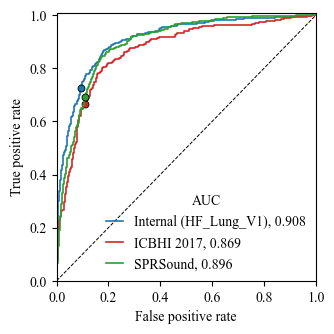

In [ ]:
# Idea: place a short legend in the empty lower-right area, below the diagonal reference line
# Goal: clear journal figure (8.2 cm single column, Times New Roman 10 pt, 300 dpi), no text crossing any line
# Source: journal_Format.docx (Ver. 2026.10.1) - "All figures/tables are clear"
short = {'HF_Lung_V1 (internal)': 'Internal (HF_Lung_V1)', 'ICBHI 2017 (external)': 'ICBHI 2017',
         'SPRSound (external)': 'SPRSound'}
fig, ax = plt.subplots(figsize=(8.2 * cm, 8.2 * cm))
for (k, (yt, p)), c in zip(sets.items(), ['#1f77b4', '#d62728', '#2ca02c']):
    fpr, tpr, _ = roc_curve(yt, p)
    ax.plot(fpr, tpr, c=c, lw=1.2, label=f'{short[k]}, {roc_auc_score(yt, p):.3f}')
    yh = p >= THR
    ax.plot((yh & (yt == 0)).sum() / (yt == 0).sum(), (yh & (yt == 1)).sum() / (yt == 1).sum(),
            'o', c=c, ms=5, mec='k', mew=0.6)
ax.plot([0, 1], [0, 1], 'k--', lw=0.7)
ax.set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc='lower right', title='AUC', frameon=False, handlelength=1.2, borderaxespad=0.3)
plt.tight_layout(pad=0.3)
for ext in ['png', 'tiff']:
    plt.savefig(f'{EV}/fig4_roc_journal_300dpi.{ext}', dpi=300)
plt.show()

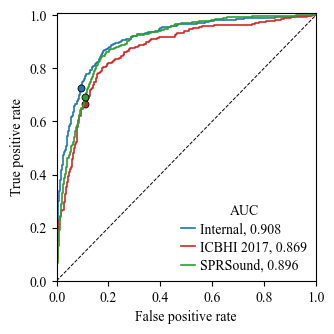

In [ ]:
# Idea: shorter legend labels so the legend sits fully right of the diagonal line, keeping 10 pt text
# Goal: clear journal figure (8.2 cm single column, Times New Roman 10 pt, 300 dpi)
# Source: journal_Format.docx (Ver. 2026.10.1) - text in figures 10 pt; figures must be clear
short = {'HF_Lung_V1 (internal)': 'Internal', 'ICBHI 2017 (external)': 'ICBHI 2017',
         'SPRSound (external)': 'SPRSound'}
fig, ax = plt.subplots(figsize=(8.2 * cm, 8.2 * cm))
for (k, (yt, p)), c in zip(sets.items(), ['#1f77b4', '#d62728', '#2ca02c']):
    fpr, tpr, _ = roc_curve(yt, p)
    ax.plot(fpr, tpr, c=c, lw=1.2, label=f'{short[k]}, {roc_auc_score(yt, p):.3f}')
    yh = p >= THR
    ax.plot((yh & (yt == 0)).sum() / (yt == 0).sum(), (yh & (yt == 1)).sum() / (yt == 1).sum(),
            'o', c=c, ms=5, mec='k', mew=0.6)
ax.plot([0, 1], [0, 1], 'k--', lw=0.7)
ax.set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc='lower right', title='AUC', frameon=False, handlelength=1.0,
          handletextpad=0.4, labelspacing=0.3, borderaxespad=0.2)
plt.tight_layout(pad=0.3)
for ext in ['png', 'tiff']:
    plt.savefig(f'{EV}/fig4_roc_journal_300dpi.{ext}', dpi=300)
plt.show()

In [ ]:
# Idea: session-clustered bootstrap for internal uncertainty and paired model differences
# Goal: 95% CIs for per-class P/R/F1/AUC of BEATs and for BEATs-minus-baseline differences (2,000 session resamples)
# Source: cluster bootstrap (Field & Welsh, J. R. Stat. Soc. B, 2007)
from google.colab import drive; drive.mount('/content/drive')
import numpy as np, pandas as pd, re, datetime as dt, collections
from sklearn.metrics import roc_auc_score
D, C = '/content/drive/MyDrive', '/content/drive/MyDrive/crnn_cache'
CLS6 = ['Inhalation','Exhalation','Crackle','Wheeze','Stridor','Rhonchi']
def add_abn(Y): Y = Y.max(1).astype(int); return np.c_[Y, Y[:, 2:6].max(1)]
Ytr, Yte = add_abn(np.load(f'{C}/train_Yf.npy')), add_abn(np.load(f'{C}/test_Yf.npy'))
fold = np.load(f'{C}/train_fold.npy'); nte = np.load(f'{C}/test_names.npy', allow_pickle=True)

# test sessions (same rule as Section 3.1)
parse = lambda n: dt.datetime.strptime(''.join(re.findall(r'\d', n))[:14], '%Y%m%d%H%M%S')
sess, s, prev = np.zeros(len(nte), int), 0, None
tr = collections.defaultdict(list)
for i, n in enumerate(nte):
    if n.startswith('trunc'): tr[parse(n)].append(i)
for g in tr.values(): sess[g] = s; s += 1
for i in sorted([i for i, n in enumerate(nte) if n.startswith('steth')], key=lambda i: parse(nte[i])):
    t = parse(nte[i]); s += prev is None or (t - prev) > dt.timedelta(minutes=10); sess[i] = s; prev = t
_, sess = np.unique(sess, return_inverse=True); print('test sessions:', sess.max() + 1)

# probabilities and OOF thresholds
def oof_of(m):
    o = np.zeros(Ytr.shape, np.float32)
    for k in range(5): o[fold == k] = np.load(f'{D}/matched_baselines/{m}/fold{k}_val_prob.npy')
    return o
M = {'BEATs': (np.load(f'{D}/beats_5fold/beats_oof_prob.npy'), np.load(f'{D}/beats_5fold/beats_test_prob.npy'))}
for name, m in [('AST','ast'), ('EfficientAT','efficientat'), ('CNN-BiGRU','crnn'), ('InceptionTime','inceptiontime')]:
    M[name] = (oof_of(m), np.load(f'{D}/matched_baselines/{m}/test_prob_5fold.npy'))
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
def best_t(y, p, obj):
    sc = [((p >= t) == y).mean() if obj == 'acc' else 2*((p >= t) & (y == 1)).sum() / max((p >= t).sum() + y.sum(), 1) for t in grid]
    return grid[int(np.argmax(sc))]
PRED = {(n, o): (M[n][1][:, :6] >= np.array([best_t(Ytr[:, c], M[n][0][:, c], o) for c in range(6)])).astype(int)
        for n in M for o in ('acc', 'f1')}

def metrics(idx, n, o):
    y, p, yp = Yte[idx, :6], M[n][1][idx, :6], PRED[(n, o)][idx]
    tp = (yp & y).sum(0); pr = tp / np.maximum(yp.sum(0), 1); rc = tp / np.maximum(y.sum(0), 1)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-9)
    auc = np.array([roc_auc_score(y[:, c], p[:, c]) if 0 < y[:, c].sum() < len(y) else np.nan for c in range(6)])
    return pr, rc, f1, auc

rng, B, S = np.random.default_rng(0), 2000, sess.max() + 1
members = [np.where(sess == k)[0] for k in range(S)]
boot = collections.defaultdict(list)
for b in range(B):
    idx = np.concatenate([members[k] for k in rng.integers(0, S, S)])
    res = {(n, o): metrics(idx, n, o) for n in M for o in ('acc', 'f1')}
    pr, rc, f1, auc = res[('BEATs', 'acc')]
    boot['P'].append(pr); boot['R'].append(rc); boot['F1'].append(f1); boot['AUC'].append(auc)
    for n in M:
        if n == 'BEATs': continue
        boot[f'dAUC {n}'].append(np.nanmean(auc) - np.nanmean(res[(n, 'acc')][3]))
        for o in ('acc', 'f1'): boot[f'dF1-{o} {n}'].append(res[('BEATs', o)][2].mean() - res[(n, o)][2].mean())
ci = lambda a: np.nanpercentile(np.array(a, float), [2.5, 97.5], axis=0)

full = metrics(np.arange(len(Yte)), 'BEATs', 'acc')
rows = []
for c in range(6):
    r = {'Class': CLS6[c], 'Positives': int(Yte[:, c].sum())}
    for k, j in zip(['P', 'R', 'F1', 'AUC'], range(4)):
        lo, hi = ci(boot[k])[:, c]; r[k] = f'{full[j][c]:.3f} ({lo:.3f}–{hi:.3f})'
    rows.append(r)
pd.set_option('display.width', 250)
print('BEATs, Accuracy-optimal thresholds, 95% session-cluster bootstrap CI (B = 2,000):'); print(pd.DataFrame(rows).to_string(index=False))
print('\nPaired differences, BEATs minus baseline (Macro over 6 classes), 95% CI:')
for k in sorted(k for k in boot if k.startswith('d')):
    a = np.array(boot[k]); print(f'{k:28s} mean {np.nanmean(a):+.3f}  CI ({ci(a)[0]:+.3f}, {ci(a)[1]:+.3f})  P(diff<=0) = {(a <= 0).mean():.3f}')

Mounted at /content/drive
test sessions: 143
BEATs, Accuracy-optimal thresholds, 95% session-cluster bootstrap CI (B = 2,000):
     Class  Positives                   P                   R                  F1                 AUC
Inhalation       1935 0.989 (0.981–0.995) 1.000 (1.000–1.000) 0.995 (0.991–0.998) 0.886 (0.787–0.965)
Exhalation        950 0.736 (0.646–0.814) 0.759 (0.677–0.828) 0.748 (0.673–0.810) 0.828 (0.780–0.870)
   Crackle        368 0.453 (0.306–0.650) 0.658 (0.581–0.725) 0.537 (0.413–0.662) 0.817 (0.746–0.879)
    Wheeze        405 0.851 (0.739–0.900) 0.509 (0.311–0.670) 0.637 (0.441–0.756) 0.922 (0.876–0.959)
   Stridor         12 0.000 (0.000–0.000) 0.000 (0.000–0.000) 0.000 (0.000–0.000) 0.821 (0.730–0.893)
   Rhonchi        296 0.822 (0.677–0.927) 0.125 (0.056–0.280) 0.217 (0.104–0.417) 0.696 (0.616–0.827)

Paired differences, BEATs minus baseline (Macro over 6 classes), 95% CI:
dAUC AST                     mean +0.023  CI (+0.005, +0.038)  P(diff<=0) = 0.009
dAU

In [ ]:
# Idea: cluster-bootstrap CIs for the external wheeze test (Table 7) under one documented method
# Goal: 95% CIs for P/R/F1/AUC — internal: session clusters; ICBHI and SPRSound: patient clusters (B = 2,000)
# Source: cluster bootstrap (Field & Welsh, J. R. Stat. Soc. B, 2007)
import glob, os
EV = '/content/drive/MyDrive/External_Validation'
for f in ['icbhi_pred.csv', 'sprsound_pred.csv', 'icbhi_recordings.csv', 'sprsound_main.csv']:
    print(f, '->', list(pd.read_csv(f'{EV}/{f}', nrows=1).columns))
THR = 0.43

def prob_col(df): return [c for c in df.columns if 'prob' in c.lower() or c.lower() in ('p', 'p_wheeze', 'score')][0]
def ext_set(pred, rec):
    p, r = pd.read_csv(f'{EV}/{pred}'), pd.read_csv(f'{EV}/{rec}')
    keep = [c for c in ['stem', 'patient', 'wheeze', 'device'] if c in r.columns and (c == 'stem' or c not in p.columns)]
    m = p.merge(r[keep], on='stem', how='left')
    if 'patient' not in m.columns or m['patient'].isna().any():
        m['patient'] = m['stem'].astype(str).str.split('_').str[0]
    return m['wheeze'].astype(int).values, m[prob_col(m)].values, pd.factorize(m['patient'])[0], m.get('device')

pin = np.load(f'{EV}/repro_test_prob_folds01.npy'); pin = pin.mean(0)[:, 3] if pin.ndim == 3 else pin[:, 3]
sets = {'HF_Lung_V1 (internal)': (Yte[:, 3], pin, sess, None)}
sets['ICBHI 2017'] = ext_set('icbhi_pred.csv', 'icbhi_recordings.csv')
sets['SPRSound'] = ext_set('sprsound_pred.csv', 'sprsound_main.csv')
y_i, p_i, g_i, dev_i = sets['ICBHI 2017']
if dev_i is not None:
    m3 = (dev_i == 'Litt3200').values; sets['ICBHI Littmann 3200'] = (y_i[m3], p_i[m3], pd.factorize(g_i[m3])[0], None)

def met(y, p):
    yp = p >= THR; tp = (yp & (y == 1)).sum(); pr = tp / max(yp.sum(), 1); rc = tp / max(y.sum(), 1)
    return [pr, rc, 2 * pr * rc / max(pr + rc, 1e-9), roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan]
rows, rng = [], np.random.default_rng(0)
for name, (y, p, g, _) in sets.items():
    G = g.max() + 1; mem = [np.where(g == k)[0] for k in range(G)]
    bs = np.array([met(y[ix], p[ix]) for ix in (np.concatenate([mem[k] for k in rng.integers(0, G, G)]) for _ in range(2000))])
    full, lo, hi = met(y, p), np.nanpercentile(bs, 2.5, 0), np.nanpercentile(bs, 97.5, 0)
    r = {'Set': name, 'N': len(y), 'Clusters': G, 'Wheeze %': round(100 * y.mean(), 1)}
    for j, k in enumerate(['Precision', 'Recall', 'F1', 'AUC']): r[k] = f'{full[j]:.3f} ({lo[j]:.3f}–{hi[j]:.3f})'
    rows.append(r)
print(f'\nWheeze, threshold {THR}, folds 1–2 ensemble, 95% cluster-bootstrap CI (B = 2,000):')
print(pd.DataFrame(rows).to_string(index=False))

icbhi_pred.csv -> ['stem', 'wheeze', 'adult', 'wav', 'sr', 'dur', 'device', 'patient', 'n_chunks', 'p_wheeze']
sprsound_pred.csv -> ['stem', 'wav', 'sr', 'ch', 'dur', 'patient', 'rec_label', 'wheeze', 'n_chunks', 'p_wheeze']
icbhi_recordings.csv -> ['stem', 'wheeze', 'adult', 'wav', 'sr', 'dur', 'device', 'patient']
sprsound_main.csv -> ['stem', 'wav', 'sr', 'ch', 'dur', 'patient', 'rec_label', 'wheeze']

Wheeze, threshold 0.43, folds 1–2 ensemble, 95% cluster-bootstrap CI (B = 2,000):
                  Set    N  Clusters  Wheeze %           Precision              Recall                  F1                 AUC
HF_Lung_V1 (internal) 1956       143      20.7 0.670 (0.523–0.760) 0.726 (0.548–0.867) 0.697 (0.564–0.790) 0.908 (0.856–0.951)
           ICBHI 2017  920       126      36.5 0.778 (0.680–0.858) 0.667 (0.585–0.749) 0.718 (0.646–0.777) 0.869 (0.828–0.906)
             SPRSound 6565      1257       9.7 0.401 (0.347–0.453) 0.692 (0.634–0.752) 0.507 (0.455–0.557) 0.896 (0.876–0.917)
 

In [ ]:
# Idea: operating-point trade-offs and calibration for BEATs (PR and ROC curves with uncertainty)
# Goal: per-class PR/ROC with 95% session-cluster bootstrap bands, both OOF operating points marked, AP, Brier score and ECE
# Source: Saito & Rehmsmeier, PLOS ONE 2015 (PR curves); Guo et al., ICML 2017 (ECE)
from google.colab import drive; drive.mount('/content/drive')
import numpy as np, re, datetime as dt, collections, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, roc_auc_score
D, C = '/content/drive/MyDrive', '/content/drive/MyDrive/crnn_cache'
CLS6 = ['Inhalation','Exhalation','Crackle','Wheeze','Stridor','Rhonchi']
Ytr = np.load(f'{C}/train_Yf.npy').max(1).astype(int); Yte = np.load(f'{C}/test_Yf.npy').max(1).astype(int)
oof = np.load(f'{D}/beats_5fold/beats_oof_prob.npy')[:, :6]; P = np.load(f'{D}/beats_5fold/beats_test_prob.npy')[:, :6]
nte = np.load(f'{C}/test_names.npy', allow_pickle=True)

parse = lambda n: dt.datetime.strptime(''.join(re.findall(r'\d', n))[:14], '%Y%m%d%H%M%S')
sess, s, prev, tr = np.zeros(len(nte), int), 0, None, collections.defaultdict(list)
for i, n in enumerate(nte):
    if n.startswith('trunc'): tr[parse(n)].append(i)
for g in tr.values(): sess[g] = s; s += 1
for i in sorted([i for i, n in enumerate(nte) if n.startswith('steth')], key=lambda i: parse(nte[i])):
    t = parse(nte[i]); s += prev is None or (t - prev) > dt.timedelta(minutes=10); sess[i] = s; prev = t
_, sess = np.unique(sess, return_inverse=True); S = sess.max() + 1; mem = [np.where(sess == k)[0] for k in range(S)]

grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
def best_t(y, p, obj):
    sc = [((p >= t) == y).mean() if obj == 'acc' else 2*((p >= t) & (y == 1)).sum() / max((p >= t).sum() + y.sum(), 1) for t in grid]
    return grid[int(np.argmax(sc))]
T = {o: [best_t(Ytr[:, c], oof[:, c], o) for c in range(6)] for o in ('acc', 'f1')}
def ece(y, p, nb=10):
    b = np.minimum((p * nb).astype(int), nb - 1)
    return sum(abs(y[b == k].mean() - p[b == k].mean()) * (b == k).mean() for k in range(nb) if (b == k).any())

rng, B, xs = np.random.default_rng(0), 2000, np.linspace(0, 1, 101)
fig, ax = plt.subplots(2, 6, figsize=(18, 6.2))
print(f'{"Class":11s} {"AP (95% CI)":22s} {"prevalence":>10s} {"Brier":>7s} {"ECE":>6s}')
for c in range(6):
    y, p = Yte[:, c], P[:, c]; tprs, precs, aps = [], [], []
    for _ in range(B):
        ix = np.concatenate([mem[k] for k in rng.integers(0, S, S)]); yb, pb = y[ix], p[ix]
        if 0 < yb.sum() < len(yb):
            f, t, _ = roc_curve(yb, pb); tprs.append(np.interp(xs, f, t))
            pr, rc, _ = precision_recall_curve(yb, pb); precs.append(np.interp(xs, rc[::-1], pr[::-1])); aps.append(average_precision_score(yb, pb))
    f, t, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
    lo_r, hi_r = np.percentile(tprs, [2.5, 97.5], 0); lo_p, hi_p = np.percentile(precs, [2.5, 97.5], 0)
    ax[0, c].fill_between(xs, lo_r, hi_r, alpha=.25); ax[0, c].plot(f, t, lw=1.4); ax[0, c].plot([0, 1], [0, 1], 'k:', lw=.8)
    ax[1, c].fill_between(xs, lo_p, hi_p, alpha=.25); ax[1, c].plot(rc, pr, lw=1.4); ax[1, c].axhline(y.mean(), color='k', ls=':', lw=.8)
    for o, mk in (('acc', 'o'), ('f1', 's')):
        yp = p >= T[o][c]; sen = (yp & (y == 1)).sum() / y.sum(); fpr = (yp & (y == 0)).sum() / (y == 0).sum(); prc = (yp & (y == 1)).sum() / max(yp.sum(), 1)
        ax[0, c].plot(fpr, sen, mk, color='k', ms=5); ax[1, c].plot(sen, prc, mk, color='k', ms=5)
    ax[0, c].set_title(f'{CLS6[c]} (n+={y.sum()})', fontsize=10); ax[0, c].set_xlabel('1 − Specificity', fontsize=9); ax[1, c].set_xlabel('Recall', fontsize=9)
    if c == 0: ax[0, c].set_ylabel('Sensitivity'); ax[1, c].set_ylabel('Precision')
    lo, hi = np.percentile(aps, [2.5, 97.5])
    print(f'{CLS6[c]:11s} {average_precision_score(y, p):.3f} ({lo:.3f}–{hi:.3f})   {y.mean():10.3f} {np.mean((p - y) ** 2):7.3f} {ece(y, p):6.3f}')
plt.tight_layout(); out = f'{D}/beats_5fold/fig_pr_roc_bootstrap_300dpi.png'; plt.savefig(out, dpi=300); plt.show(); print('saved:', out)
print('OOF thresholds — Accuracy-optimal (circle):', T['acc'], '| F1-optimal (square):', T['f1'])

In [ ]:
# Idea: device-wise failure analysis and inference cost of BEATs
# Goal: per-class AUC/recall by recording device (steth_ = Littmann 3200, trunc_ = HF-Type-1); latency, memory and size of 1 vs 5 models
# Source: BEATs official code (Chen et al., ICML 2023)
from google.colab import drive; drive.mount('/content/drive')
import numpy as np, torch, torch.nn as nn, time, sys, os
from sklearn.metrics import roc_auc_score
D, C = '/content/drive/MyDrive', '/content/drive/MyDrive/crnn_cache'
CLS6 = ['Inhalation','Exhalation','Crackle','Wheeze','Stridor','Rhonchi']

# 1) device-wise analysis (Accuracy-optimal OOF thresholds)
Ytr = np.load(f'{C}/train_Yf.npy').max(1).astype(int); Yte = np.load(f'{C}/test_Yf.npy').max(1).astype(int)
oof = np.load(f'{D}/beats_5fold/beats_oof_prob.npy')[:, :6]; P = np.load(f'{D}/beats_5fold/beats_test_prob.npy')[:, :6]
nte = np.load(f'{C}/test_names.npy', allow_pickle=True); dev_ = np.array(['Littmann 3200' if n.startswith('steth') else 'HF-Type-1' for n in nte])
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
T = [grid[int(np.argmax([((oof[:, c] >= t) == Ytr[:, c]).mean() for t in grid]))] for c in range(6)]
print(f'{"Class":11s}', ''.join(f'| {d:28s}' for d in ['Littmann 3200 (steth_)', 'HF-Type-1 (trunc_)']))
for c in range(6):
    row = f'{CLS6[c]:11s}'
    for d in ['Littmann 3200', 'HF-Type-1']:
        m = dev_ == d; y, p = Yte[m, c], P[m, c]; n = y.sum()
        auc = roc_auc_score(y, p) if 0 < n < len(y) else float('nan'); rc = ((p >= T[c]) & (y == 1)).sum() / max(n, 1)
        row += f'| n+={n:4d} AUC {auc:.3f} recall {rc:.3f} '
    print(row)
print('recordings per device:', {d: int((dev_ == d).sum()) for d in ['Littmann 3200', 'HF-Type-1']})

# 2) inference cost of one BEATs model and the five-model ensemble (15-s recording, 16 kHz input)
sys.path.insert(0, f'{D}/models/beats_code'); from BEATs import BEATs, BEATsConfig
ck = torch.load(f'{D}/models/BEATs_iter3_plus_AS2M.pt', map_location='cpu', weights_only=False)
class Net(nn.Module):
    def __init__(s):
        super().__init__(); s.beats = BEATs(BEATsConfig(ck['cfg'])); s.beats.load_state_dict(ck['model'], strict=False)
        s.norm, s.fc = nn.LayerNorm(768), nn.Linear(768, 7)
    def forward(s, w):
        h = s.beats.extract_features(w, padding_mask=None)[0]; h = h.reshape(h.shape[0], -1, 8, 768).mean(2)
        return torch.nn.functional.interpolate(s.fc(s.norm(h)).transpose(1, 2), size=938, mode='linear', align_corners=False)
m = Net().eval(); n_par = sum(p.numel() for p in m.parameters())
print(f'\nparameters per model: {n_par/1e6:.1f} M | ensemble: {5*n_par/1e6:.1f} M | fp32 weights: {4*n_par/1e6:.0f} MB per model, {20*n_par/1e6:.0f} MB for five')
w = torch.randn(1, 16000 * 15) * 0.1
def bench(model, x, dev, reps):
    model.to(dev); x = x.to(dev)
    with torch.no_grad():
        for _ in range(3): model(x)
        if dev == 'cuda': torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        for _ in range(reps): model(x)
        if dev == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps * 1000
g = bench(m, w, 'cuda', 20); mem = torch.cuda.max_memory_allocated() / 1e9
print(f'GPU ({torch.cuda.get_device_name(0)}): {g:.0f} ms per recording, single model | {5*g:.0f} ms for five models | peak memory {mem:.2f} GB')
c_ = bench(m, w, 'cpu', 3)
print(f'CPU ({os.cpu_count()} threads): {c_:.0f} ms per recording, single model | {5*c_:.0f} ms for five models | real-time factor (five models) {5*c_/15000:.3f}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Class       | Littmann 3200 (steth_)      | HF-Type-1 (trunc_)          
Inhalation | n+=1229 AUC 0.903 recall 1.000 | n+= 706 AUC nan recall 1.000 
Exhalation | n+= 568 AUC 0.817 recall 0.729 | n+= 382 AUC 0.841 recall 0.804 
Crackle    | n+= 338 AUC 0.871 recall 0.678 | n+=  30 AUC 0.668 recall 0.433 
Wheeze     | n+= 116 AUC 0.936 recall 0.500 | n+= 289 AUC 0.893 recall 0.512 
Stridor    | n+=   9 AUC 0.869 recall 0.000 | n+=   3 AUC 0.873 recall 0.000 
Rhonchi    | n+= 109 AUC 0.917 recall 0.330 | n+= 187 AUC 0.642 recall 0.005 
recordings per device: {'Littmann 3200': 1250, 'HF-Type-1': 706}


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)



parameters per model: 90.3 M | ensemble: 451.6 M | fp32 weights: 361 MB per model, 1806 MB for five


AssertionError: Torch not compiled with CUDA enabled

In [ ]:
# Idea: CPU inference cost of one BEATs model and the five-model ensemble
# Goal: latency per 15-s recording and real-time factor on the Colab CPU runtime
# Source: -
import platform, subprocess
cpu = subprocess.run("lscpu | grep 'Model name'", shell=True, capture_output=True, text=True).stdout.split(':')[-1].strip()
c_ = bench(m, w, 'cpu', 5)
print(f'CPU: {cpu} ({os.cpu_count()} threads)')
print(f'single model: {c_:.0f} ms per 15-s recording | five models: {5*c_:.0f} ms | real-time factor (five models): {5*c_/15000:.3f}')

CPU: Intel(R) Xeon(R) CPU @ 2.20GHz (2 threads)
single model: 4292 ms per 15-s recording | five models: 21460 ms | real-time factor (five models): 1.431
